In [32]:
import pandas as pd
import scipy.stats
import umap
from matplotlib import gridspec
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib
import numpy as np
from sklearn.decomposition import PCA
import torch
import os
import sys
from BWM.models.isometric_autoencoder import get_density_proxy
# Add project root to path
sys.path.append(os.path.abspath('../../'))

from BWM.bwm_functions import *
from BWM.models.isometric_autoencoder import SklearnIsometricAutoencoder

plt.rcParams["axes.grid"] = False
matplotlib.rcParams['axes.linewidth'] = .5

# Set global plotting parameters for font size
tick_fontsize = 6
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.size': 7,
    'axes.titlesize': 7,
    'axes.labelsize': 7,
    'xtick.labelsize': tick_fontsize,
    'ytick.labelsize': tick_fontsize,
    'legend.fontsize': 7,
    'figure.titlesize': 7
})

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")


Using device: cpu


In [33]:
# Set directory path and select an EID
directory_path = '../Data2'
all_items = os.listdir(directory_path)
eids = [item for item in all_items if os.path.isdir(os.path.join(directory_path, item))]


In [34]:
# Data loading using get_region_response_matrix
region = 'CP' # Caudoputamen
pseudo_response_tensor, condition_matrix, neuron_eids = get_region_response_matrix(
    eids=eids,
    directory_path=directory_path,
    region=region,
    mapping='Beryl',
    sigma=5,
    n_steps=100,
    threshold=5,
    min_trials_per_condition=50,
    n_pseudo=25,
    conditions=['choice'],
    event="stimOn_times",
    filter_significant=True,
    significance_threshold=0.5
)




Aggregating CP responses across 459 EIDs...


Dispatching jobs:  24%|██▍       | 112/459 [00:38<01:55,  3.00it/s]/Users/cl1704/anaconda3/envs/embedding_env/lib/python3.9/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(
Numba: Attempted to fork from a non-main thread, the TBB library may be in an invalid state in the child process.
Dispatching jobs:  31%|███▏      | 144/459 [00:46<01:31,  3.43it/s]Numba: Attempted to fork from a non-main thread, the TBB library may be in an invalid state in the child process.
Numba: Attempted to fork from a non-main thread, the TBB library may be in an invalid state in the child process.
Dispatching jobs:  42%|████▏     | 192/459 [01:11<02:11,  2.04it/s]Numba: Attempted to fork from a non-main thread, the TBB library may be in an invalid state in the child process.
Numba: Attempted to fork from a non-main thread, the TBB library

Max conditions: 2, Common conditions found: [(np.float64(-1.0),), (np.float64(1.0),)]
Total neurons collected: 7946


In [35]:
def iso_ae_preprocessing(pseudo_response_tensor):
    response_tensor = np.mean(pseudo_response_tensor, axis=0)
    # Z-score and reshape
    response_tensor_norm = (response_tensor - np.mean(response_tensor, axis=(0, 1), keepdims=True)) / (np.std(response_tensor, axis=(0, 1), keepdims=True) + 1e-8)
    response_matrix = response_tensor_norm.reshape(-1, response_tensor_norm.shape[2])

    X_transposed = response_matrix.T

    # Scale each row (neuron) to unit length
    row_norms = np.linalg.norm(X_transposed, axis=1, keepdims=True)
    X_pre_pca = X_transposed / (row_norms + 1e-8)

    # Reduce features to 20 using PCA

    return X_pre_pca

X = iso_ae_preprocessing(pseudo_response_tensor)

In [36]:
def calculate_msd(response_matrix):
    """
    Calculate Mean Standardized Derivative using finite differences.
    responses: (conditions, time, neurons)
    """
    response_matrix_expand = response_matrix.reshape( response_matrix.shape[0],100,2)
    diff_responses = np.diff(response_matrix_expand, axis=1)
    # Absolute standardized derivative (already standardized in the previous cell)
    # Mean over conditions and time and pseudo trials
    msd = np.mean(np.abs(diff_responses), axis=(1, 2))
    return msd

msd = calculate_msd(X)

In [37]:
import numpy as np

def deform_neuron_data(data):
    """
    Randomly deforms a time series array of shape (n_neurons, 200) by splitting
    each neuron's data into two 100-step time series, randomizing their Fourier phases
    to preserve mean, std, and mean derivative, and returning the reconstructed array.
    """
    n_neurons, total_steps = data.shape
    if total_steps != 200:
        raise ValueError(f"Expected second dimension to be 200, got {total_steps}")

    # Initialize the output array with the same shape
    deformed_data = np.zeros_like(data)

    # Calculate symmetry properties once for a length-100 time series
    n_ts = 100
    half_len = (n_ts - 1) // 2  # For 100, this is 49

    for i in range(n_neurons):
        # Split into the two distinct 100-step segments
        segments = [data[i, :100], data[i, 100:]]
        deformed_segments = []

        for seg in segments:
            # 1. Fourier Transform
            fft_vals = np.fft.fft(seg)
            amplitude = np.abs(fft_vals)

            # 2. Generate symmetric random phases to keep the signal real
            random_phase = np.zeros(n_ts)
            phases_to_add = np.random.uniform(-np.pi, np.pi, half_len)

            # Assign positive frequencies
            random_phase[1:1+half_len] = phases_to_add
            # Assign negative frequencies (complex conjugate symmetry)
            random_phase[-half_len:] = -phases_to_add[::-1]

            # 3. Reconstruct in frequency domain and invert back to time domain
            new_fft = amplitude * np.exp(1j * random_phase)
            deformed_seg = np.fft.ifft(new_fft).real

            deformed_segments.append(deformed_seg)

        # Concatenate the two 100-step deformed segments back into a 200-step row
        deformed_data[i, :] = np.concatenate(deformed_segments)

    return deformed_data

/var/folders/9_/yjc4d8zx4tj6kw6h4xgj4zd80000gn/T/ipykernel_71619/1616727503.py:78: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


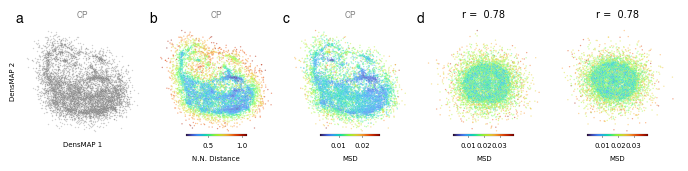

In [39]:
fig, axes = plt.subplots(nrows=1, ncols=5, figsize=(7, 1.5), sharey=False)
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

z_neurons = umap.UMAP(densmap=True, dens_lambda=2, n_neighbors = 500).fit_transform(X)
loc_density  = get_density_proxy(X, k=50)
sns.scatterplot(x=z_neurons[:, 0], y=z_neurons[:, 1], color='gray', s=1, alpha=.35,ax=axes[0])
sns.scatterplot(x=z_neurons[:, 0], y=z_neurons[:, 1], c=loc_density,cmap='turbo', s=1, alpha=.5,ax=axes[1])
cax = inset_axes(
        axes[1], width="50%", height="2%",
        loc="lower center", borderpad=0
    )

norm = plt.Normalize(loc_density.min(), loc_density.max())
sm = plt.cm.ScalarMappable(cmap="turbo", norm=norm)
cb = fig.colorbar(sm, cax=cax, orientation="horizontal")
cb.outline.set_linewidth(0.1)
cax.set_xlabel("N.N. Distance", fontsize=5, labelpad=5)
cax.xaxis.set_tick_params(size=1, width=.5, color="black")
cax.xaxis.set_tick_params(labelsize=5)

# MSD
sns.scatterplot(x=z_neurons[:, 0], y=z_neurons[:, 1], c=msd,cmap='turbo', s=1, alpha=.5,ax=axes[2])
cax = inset_axes(
        axes[2], width="50%", height="2%",
        loc="lower center", borderpad=0
    )
norm = plt.Normalize(msd.min(), msd.max())
sm = plt.cm.ScalarMappable(cmap="turbo", norm=norm)
cb = fig.colorbar(sm, cax=cax, orientation="horizontal")
cb.outline.set_linewidth(0.1)
cax.set_xlabel("MSD", fontsize=5, labelpad=5)
cax.xaxis.set_tick_params(size=1, width=.5, color="black")
cax.xaxis.set_tick_params(labelsize=5)

# Rotation 1

X_rotated = deform_neuron_data(X)
loc_density  = get_density_proxy(X_rotated, k=50)
msd_rotated = calculate_msd(X_rotated)
z_neurons = umap.UMAP(densmap=True, dens_lambda=2, n_neighbors = 500).fit_transform(X_rotated)
sns.scatterplot(x=z_neurons[:, 0], y=z_neurons[:, 1], c=msd_rotated,cmap='turbo', s=1, alpha=.5,ax=axes[3])
cax = inset_axes(
        axes[3], width="50%", height="2%",
        loc="lower center", borderpad=0
    )
norm = plt.Normalize(msd_rotated.min(), msd_rotated.max())
sm = plt.cm.ScalarMappable(cmap="turbo", norm=norm)
cb = fig.colorbar(sm, cax=cax, orientation="horizontal")
cb.outline.set_linewidth(0.1)
cax.set_xlabel("MSD", fontsize=5, labelpad=5)
cax.xaxis.set_tick_params(size=1, width=.5, color="black")
cax.xaxis.set_tick_params(labelsize=5)
r_1 =scipy.stats.spearmanr(msd_rotated, loc_density)

# Rotation 2
X_rotated = deform_neuron_data(X)
loc_density  = get_density_proxy(X_rotated, k=50)
msd_rotated = calculate_msd(X_rotated)
z_neurons = umap.UMAP(densmap=True, dens_lambda=2, n_neighbors = 500).fit_transform(X_rotated)
sns.scatterplot(x=z_neurons[:, 0], y=z_neurons[:, 1], c=msd_rotated,cmap='turbo', s=1, alpha=.5,ax=axes[4])
cax = inset_axes(
        axes[4], width="50%", height="2%",
        loc="lower center", borderpad=0
    )
norm = plt.Normalize(msd_rotated.min(), msd_rotated.max())
sm = plt.cm.ScalarMappable(cmap="turbo", norm=norm)
cb = fig.colorbar(sm, cax=cax, orientation="horizontal")
cb.outline.set_linewidth(0.1)
cax.set_xlabel("MSD", fontsize=5, labelpad=5)
cax.xaxis.set_tick_params(size=1, width=.5, color="black")
cax.xaxis.set_tick_params(labelsize=5)
r_2 =scipy.stats.spearmanr(msd_rotated, loc_density)

# 4. Global figure customizations
#fig.suptitle("Main Title for All 5 Subplots", fontsize=18, fontweight="bold", y=1.05)

# Automatically adjusts subplot parameters so that the labels don't overlap
plt.tight_layout()
for ax in axes.flatten():
    for spine in ax.spines.values():
        spine.set_visible(False)

    # 2. Hide the tick marks and tick numbers
    ax.set_xticks([])
    ax.set_yticks([])

    # 3. Add your labels normally
    ax.set_xlabel('')
    ax.set_ylabel('')
axes[0].set_xlabel('DensMAP 1',fontsize = 5)
axes[0].set_ylabel('DensMAP 2',fontsize = 5)
fig.subplots_adjust(wspace=0.1)

# Figure labels
axes[0].text(-0.05, 1., 'a', transform=axes[0].transAxes,
         fontsize=10, fontweight='bold', va='bottom', ha='left',fontname = 'Helvetica')
axes[1].text(-0.05, 1, 'b', transform=axes[1].transAxes,
         fontsize=10, fontweight='bold', va='bottom', ha='left',fontname = 'Helvetica')
axes[2].text(-0.05, 1, 'c', transform=axes[2].transAxes,
         fontsize=10, fontweight='bold', va='bottom', ha='left',fontname = 'Helvetica')
axes[3].text(-0.05, 1, 'd', transform=axes[3].transAxes,
         fontsize=10, fontweight='bold', va='bottom', ha='left',fontname = 'Helvetica')

# Subfigure titles
axes[0].set_title('CP',fontsize = 6,fontname = 'Helvetica',alpha = .5)
axes[1].set_title('CP',fontsize = 6,fontname = 'Helvetica',alpha = .5)
axes[2].set_title('CP',fontsize = 6,fontname = 'Helvetica',alpha = .5)
#axes[4].set_title('Rotation 2',fontsize = 6,fontname = 'Helvetica')
#axes[3].set_title('Rotation 1',fontsize = 6,fontname = 'Helvetica')
axes[3].set_title(f"r =  {r_1[0]:.2f}")
axes[4].set_title(f"r =  {r_2[0]:.2f}")
# 5. Display or save the plot
plt.savefig("CPRotations.png", bbox_inches='tight', dpi=300)
plt.show()

In [31]:
loc_density  = get_density_proxy(X, k=50)
scipy.stats.spearmanr(msd, loc_density)

SignificanceResult(statistic=np.float64(0.736120701082419), pvalue=np.float64(0.0))

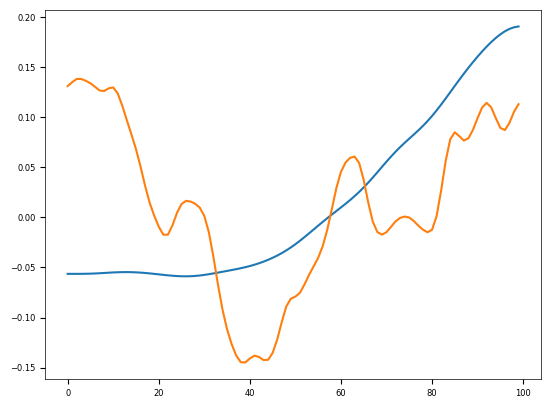

In [26]:
plt.figure()
plt.plot(X[4,:100])
plt.plot(X_rotated[4,:100])

In [ ]:
fig, axes = plt.subplots(nrows=1, ncols=5, figsize=(8, 1.5), sharey=False)
"""
Plots the distribution of a coefficient list and draws a vertical line at r
with a completely clean background (no grid lines).
"""

# Null distribution
z  = get_density_proxy(X, k=50)
r,_ = scipy.stats.spearmanr(msd, z)
coeffs = []
for i in range(1000):
    print(i)
    #Q =scipy.stats.ortho_group.rvs(X.shape[1])
    #Q = generate_constrained_orthogonal_matrix(X.shape[1], np.random.rand())
    #rotated_X = X @ Q
    rotated_X = deform_neuron_data(X)
    diff_responses = np.diff(rotated_X, axis=1)
    msd_rotated = np.mean(np.abs(diff_responses), 1)
    coeff,_ = scipy.stats.spearmanr(msd_rotated, z)
    coeffs.append(coeff)
coeffs = np.asarray(coeffs)
sns.histplot(coeffs, kde=False,color='k',legend=False,ax=axes[0])
axes[0].axvline(x=r, color="#d9534f", linestyle="--", linewidth=1,
            label=f"Reference Value ($r$ = {r:.3f})",alpha = .5)
p_value = np.sum(coeffs>r)/len(coeffs)

# # Perturbations
# coeffs = []
# for i in range(1000):
#     #Q =scipy.stats.ortho_group.rvs(X.shape[1])
#     Q = generate_constrained_orthogonal_matrix(X.shape[1], 2*np.random.rand())
#     rotated_X = X @ Q
#
#     diff_responses = np.diff(rotated_X, axis=1)
#     msd_rotated = np.mean(np.abs(diff_responses), 1)
#     coeff,_ = scipy.stats.spearmanr(msd_rotated, z)
#     coeffs.append(coeff)
# coeffs = np.asarray(coeffs)
# sns.histplot(coeffs, kde=False,color='k',legend=False,ax=axes[1])
# axes[1].axvline(x=r, color="#d9534f", linestyle="--", linewidth=1,
#             label=f"Reference Value ($r$ = {r:.3f})",alpha = .5)
# p_value_2 = np.sum(coeffs>r)/len(coeffs)

# Time series 1
axes[2].plot(X[0,:100])
axes[2].plot(X[0,100:])

# Time series 2
#Q =generate_constrained_orthogonal_matrix(X.shape[1], 4)
rotated_X = deform_neuron_data(X)
axes[3].plot(rotated_X[0,:100])
axes[3].plot(rotated_X[0,100:])

# Time series 3
Q =generate_constrained_orthogonal_matrix(X.shape[1], 10)
rotated_X = X @ Q
axes[4].plot(rotated_X[0,:100])
axes[4].plot(rotated_X[0,100:])

# 3. Aesthetics and Labels
#plt.title("Distribution of Coefficients", fontsize=12, fontweight='bold', pad=12)


# Titles
axes[0].set_title(f"p =  {p_value:.2f}")
axes[1].set_title(f"p =  {p_value_2:.2f}")
# Axis labels
axes[0].set_xlabel(r'$r(\delta, MSD)$')
# Explicitly turn off the grid lines
plt.grid(False)

# Clean up the spines (border boxes) for a minimal look
sns.despine()

#plt.legend(frameon=True, facecolor='white', edgecolor='none')
plt.tight_layout()
plt.show()
